# Project 1 — Insurance Customer & Cost Analytics
**Portfolio focus:** Exploratory data analysis, visualisation, and business recommendations  
**Tools:** Python, Pandas, Matplotlib, Seaborn

## Business question
Which customer characteristics are associated with higher medical insurance charges, and what should an analyst investigate before using these patterns for business decisions?

> This is a learning project using the public `insurance.csv` dataset hosted by PyCaret. Associations are descriptive, not proof of causation, and this dataset is not a substitute for a real insurer's policy or claims data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

url = "https://raw.githubusercontent.com/pycaret/pycaret/master/datasets/insurance.csv"
try:
    df = pd.read_csv(url)
except Exception as exc:
    raise RuntimeError(
        "Could not download the public dataset. In Colab, upload insurance.csv "
        "and replace the previous line with: df = pd.read_csv('/content/insurance.csv')"
    ) from exc

print("Shape:", df.shape)
display(df.head())
display(df.info())

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


None

In [2]:
# 1. Data quality checks
print("Missing values by column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)

Missing values by column:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


Average charge: 13270.42
Median charge: 9382.03
90th percentile: 34831.72


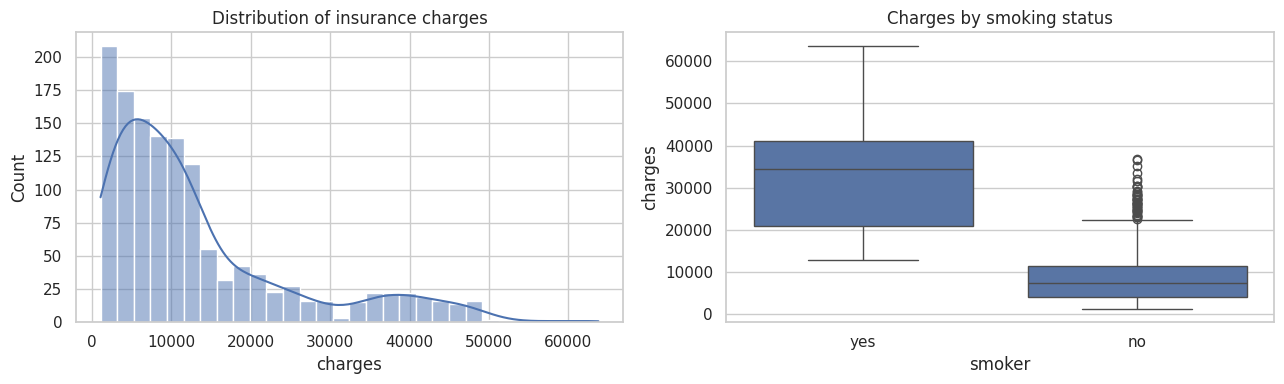

In [3]:
# 2. Basic cost profile
target = "charges"
print("Average charge:", round(df[target].mean(), 2))
print("Median charge:", round(df[target].median(), 2))
print("90th percentile:", round(df[target].quantile(0.90), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[target], kde=True, ax=axes[0])
axes[0].set_title("Distribution of insurance charges")
sns.boxplot(data=df, x="smoker", y=target, ax=axes[1])
axes[1].set_title("Charges by smoking status")
plt.tight_layout()
plt.show()

In [4]:
# 3. Segment comparisons
for col in ["sex", "smoker", "region", "children"]:
    summary = df.groupby(col, dropna=False)[target].agg(["count", "mean", "median"]).sort_values("mean", ascending=False)
    print(f"\nCharges by {col}")
    display(summary.round(2))


Charges by sex


,count,mean,median
sex,,,
male,676,13956.75,9369.62
female,662,12569.58,9412.96



Charges by smoker


,count,mean,median
smoker,,,
yes,274,32050.23,34456.35
no,1064,8434.27,7345.41



Charges by region


,count,mean,median
region,,,
southeast,364,14735.41,9294.13
northeast,324,13406.38,10057.65
northwest,325,12417.58,8965.80
southwest,325,12346.94,8798.59



Charges by children


,count,mean,median
children,,,
3,157,15355.32,10600.55
2,240,15073.56,9264.98
4,25,13850.66,11033.66
1,324,12731.17,8483.87
0,574,12365.98,9856.95
5,18,8786.04,8589.57


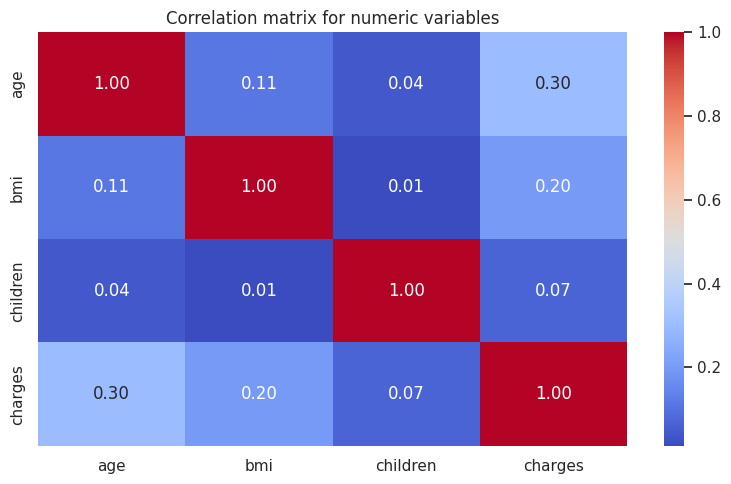

In [5]:
# 4. Relationship between numeric variables and charges
numeric_cols = df.select_dtypes(include=np.number).columns
corr = df[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix for numeric variables")
plt.tight_layout()
plt.show()

In [6]:
# 5. Simple, transparent analysis summary
smoker_means = df.groupby("smoker")[target].mean()
if {"yes", "no"}.issubset(set(smoker_means.index.astype(str))):
    ratio = smoker_means.loc["yes"] / smoker_means.loc["no"]
    print(f"Average charges for smokers are approximately {ratio:.1f}x the average for non-smokers in this dataset.")
print("Remember: a group difference is descriptive and does not establish causality.")

Average charges for smokers are approximately 3.8x the average for non-smokers in this dataset.
Remember: a group difference is descriptive and does not establish causality.


In [7]:

# Inspect duplicate records before deciding what to do
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:")
display(duplicates)

print("Total duplicate rows beyond the first occurrence:", df.duplicated().sum())


Rows involved in duplicates:


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


Total duplicate rows beyond the first occurrence: 1


In [8]:

# Compare average and median charges by smoking status
smoker_analysis = df.groupby("smoker")["charges"].agg(
    ["count", "mean", "median"]
).round(2)

display(smoker_analysis)


,count,mean,median
smoker,,,
no,1064,8434.27,7345.41
yes,274,32050.23,34456.35


## Findings to write after running
Complete these with your actual outputs:
1. Customer segment differences: Smoking status showed the strongest observed difference in average insurance charges among the comparisons examined. Customers classified as smokers had average charges of $32,050.23, compared with $8,434.27 for non-smokers. This represents a difference of $23,615.96, with smokers recording approximately 3.8 times the average charges of non-smokers. This association warrants further investigation but should not be interpreted as proof of causation.
2. Distribution of charges: Average insurance charges ($13,270.42) exceed the median ($9,382.03), suggesting a positively skewed distribution. Charges range from approximately $1,121.87 to $63,770.43, indicating substantial variation in customer costs.
3. Data-quality assessment: The dataset contains 1,338 records across seven columns, with no missing values detected. However, one duplicate row was identified and requires investigation before finalising the dataset for analysis.


## Business recommendations

Based on the observed differences in insurance charges, the following actions are recommended:

1. **Investigate cost drivers:** Examine why average charges differ substantially between smokers and non-smokers. Assess the influence of age, BMI, and other customer characteristics before drawing conclusions.

2. **Strengthen risk assessment:** Use validated, relevant data to understand customer risk profiles and improve analytical decision-making. Avoid relying on smoking status or any single characteristic in isolation.

3. **Improve cost forecasting:** Develop further statistical models to identify patterns associated with higher insurance costs and support more informed financial planning.

4. **Promote preventive health initiatives:** Where appropriate, consider customer education and wellness programmes that encourage healthier lifestyle choices, without assuming that individual outcomes can be predicted from group averages.

5. **Validate findings before implementation:** Test these observations against current, representative data and obtain appropriate actuarial and compliance review before using them in underwriting, pricing, or customer decisions.

## Limitations

This analysis uses a public educational dataset and describes associations rather than causal relationships. The findings may not generalise to a specific insurance market or customer population. They should not be treated as actuarial pricing recommendations without further validation.
